In [1]:
import kagglehub
import os


# Download latest version
path = kagglehub.dataset_download("abdullahcetin/mirichoi0218insurance")
print("Path to dataset files:", path)
print(os.listdir(path))
path += "/insurance.csv"
print(path)

Path to dataset files: C:\Users\sadan\.cache\kagglehub\datasets\abdullahcetin\mirichoi0218insurance\versions\1
['insurance.csv']
C:\Users\sadan\.cache\kagglehub\datasets\abdullahcetin\mirichoi0218insurance\versions\1/insurance.csv


## EDA

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(path)

### Basic Data Audit

In [4]:
print(df.head())
print(df.info())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB
None


**Inference**
1. There are no null values
2. age, bmi, children are numerical data, sex, smoker, region are categorical and target is charges


### Check duplicated

In [5]:
print("No of rows duplicated: ",df.duplicated().sum())
print("No of rows before removing duplicate", len(df))
df = df.drop_duplicates()
print("No of rows before removing duplicate", len(df))

No of rows duplicated:  1
No of rows before removing duplicate 1338
No of rows before removing duplicate 1337


### Missing value
- There is no missing value hence we can skip this step

## Univariate analysis

In [6]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


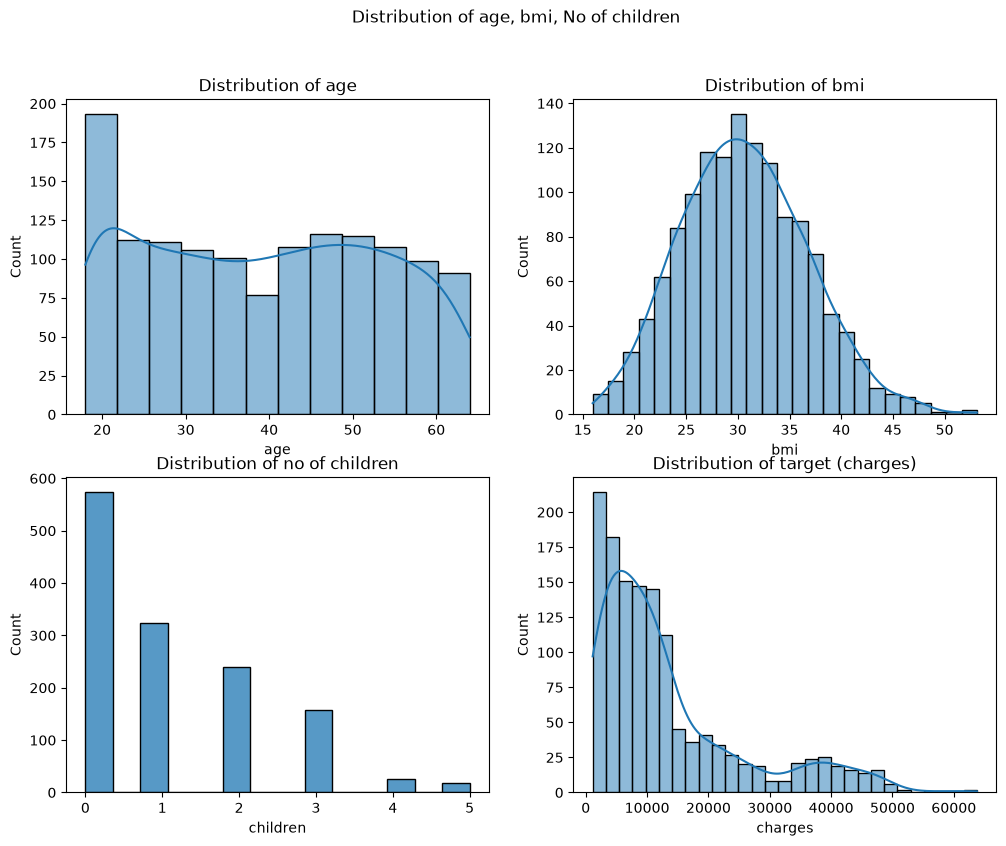

In [7]:
plt.figure(figsize=(12,9))

plt.subplot(2,2,1)
plt.suptitle("Distribution of age, bmi, No of children")
sns.histplot(df, x="age", kde=True)
plt.title("Distribution of age")

plt.subplot(2,2,2)
sns.histplot(df, x="bmi", kde=True)
plt.title("Distribution of bmi")

plt.subplot(2,2,3)
sns.histplot(df, x="children")
plt.title("Distribution of no of children")

plt.subplot(2,2,4)
sns.histplot(df, x="charges", kde=True)
plt.title("Distribution of target (charges)")
plt.show()


In [8]:
## Categorical
print(df["region"].value_counts())
print(df["sex"].value_counts())
print(df["smoker"].value_counts())

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
sex
male      675
female    662
Name: count, dtype: int64
smoker
no     1063
yes     274
Name: count, dtype: int64


<Axes: title={'center': 'Distribution with repect to smoker'}, xlabel='region', ylabel='count'>

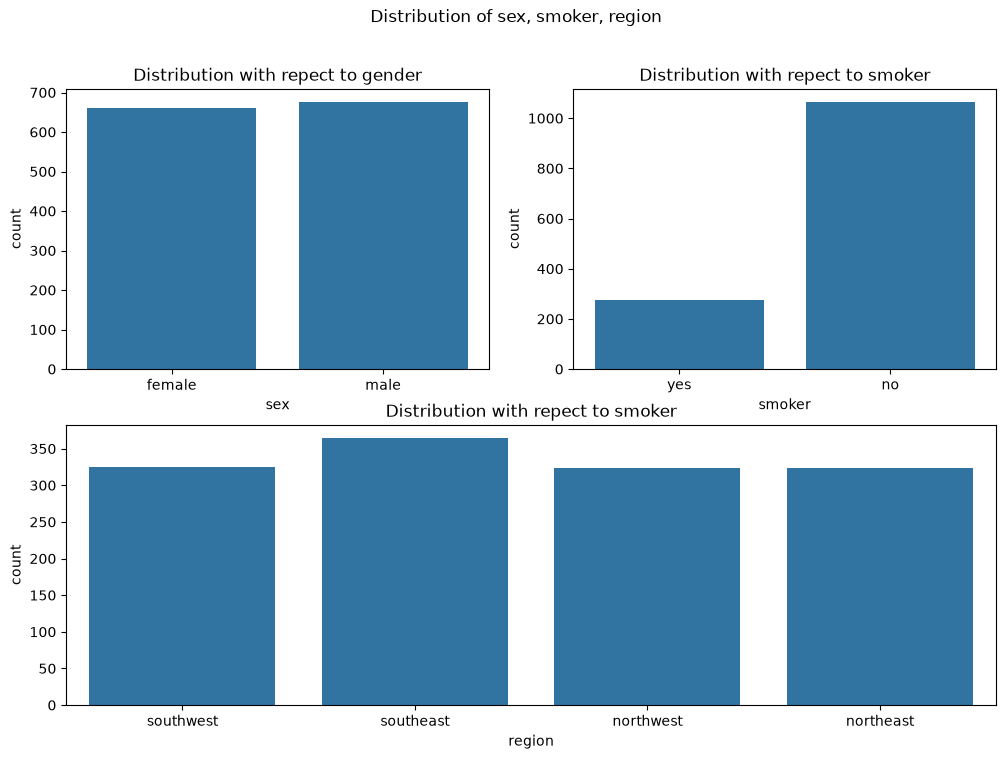

In [9]:
plt.figure(figsize=(12,8))
plt.suptitle("Distribution of sex, smoker, region")
plt.subplot(2,2,1)
plt.title("Distribution with repect to gender")
sns.countplot(df, x="sex")

plt.subplot(2,2,2)
plt.title("Distribution with repect to smoker")
sns.countplot(df, x="smoker")

plt.subplot(2,2,(3,4))
plt.title("Distribution with repect to smoker")
sns.countplot(df, x="region")

## Bivariate Analysis

In [10]:
df.corr(numeric_only=True)

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


<Axes: >

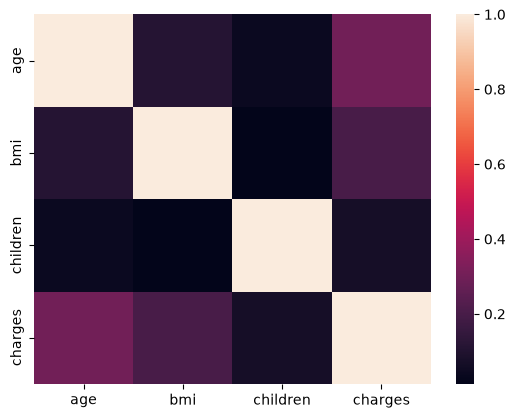

In [11]:
sns.heatmap(df.corr(numeric_only=True))

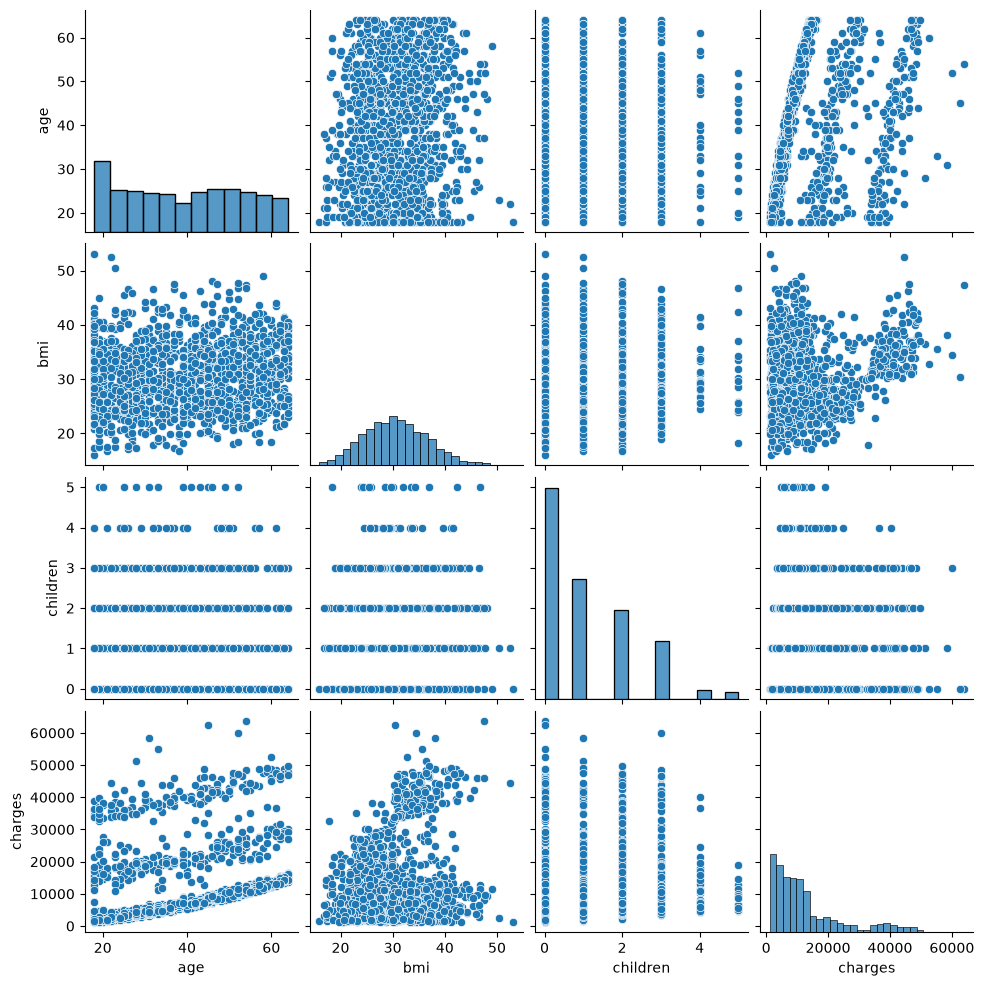

In [12]:
sns.pairplot(df)

<Axes: title={'center': 'Influnce of gender to insurance charge'}, xlabel='sex', ylabel='charges'>

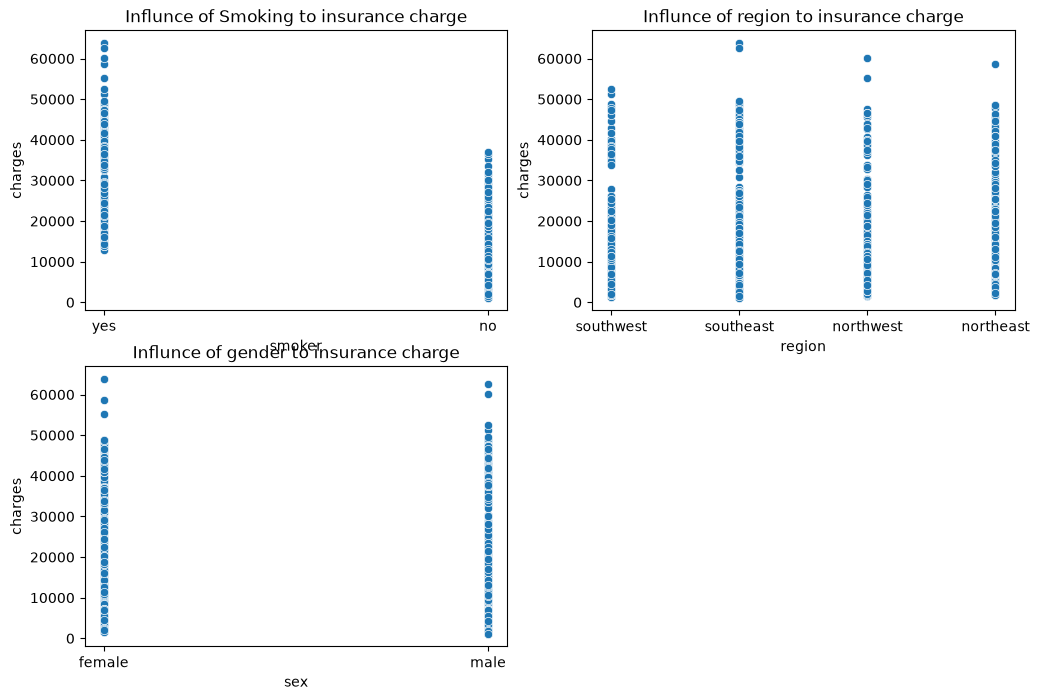

In [13]:
plt.figure(figsize=(12,8))
plt.subplot(221)
plt.title("Influnce of Smoking to insurance charge")
sns.scatterplot(df, x="smoker", y="charges")

plt.subplot(222)
plt.title("Influnce of region to insurance charge")
sns.scatterplot(df, x="region", y="charges")


plt.subplot(223)
plt.title("Influnce of gender to insurance charge")
sns.scatterplot(df, x="sex", y="charges")

## Multivariate Analysis

Text(0.5, 1.0, 'Charges by Smoking Status')

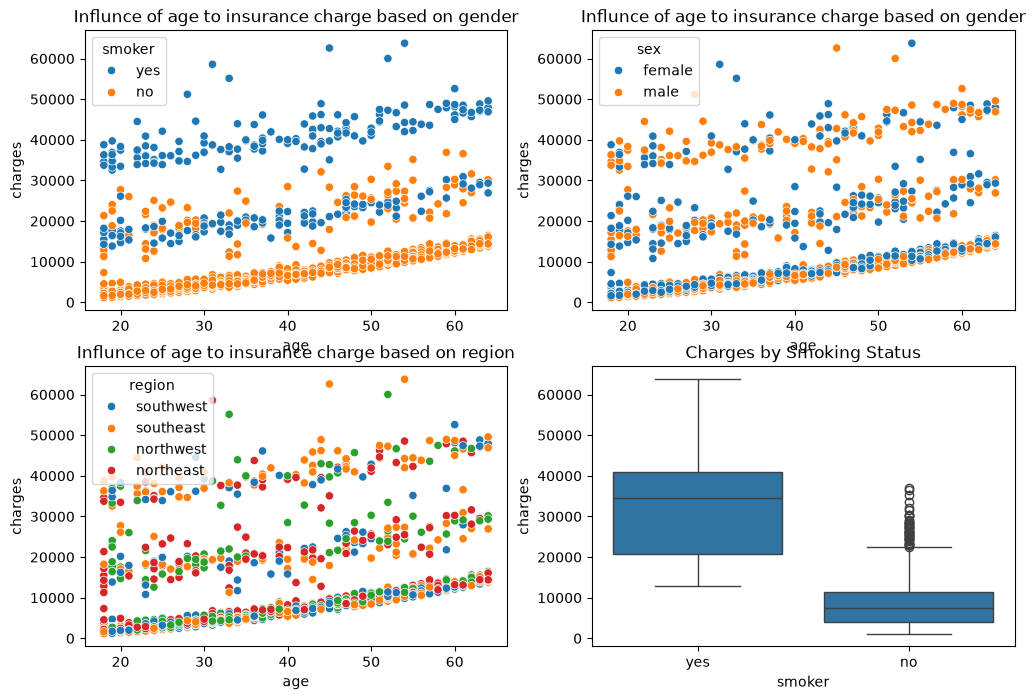

In [14]:
plt.figure(figsize=(12,8))
plt.subplot(221)
plt.title("Influnce of age to insurance charge based on gender")
sns.scatterplot(df, x="age", y="charges", hue="smoker")

plt.subplot(222)
plt.title("Influnce of age to insurance charge based on gender")
sns.scatterplot(df, x="age", y="charges", hue="sex")


plt.subplot(223)
plt.title("Influnce of age to insurance charge based on region")
sns.scatterplot(df, x="age", y="charges", hue="region")

plt.subplot(224)
sns.boxplot(x="smoker", y="charges", data=df)
plt.title("Charges by Smoking Status")

<Axes: title={'center': 'Influnce of bmi to insurance charge based on region'}, xlabel='bmi', ylabel='charges'>

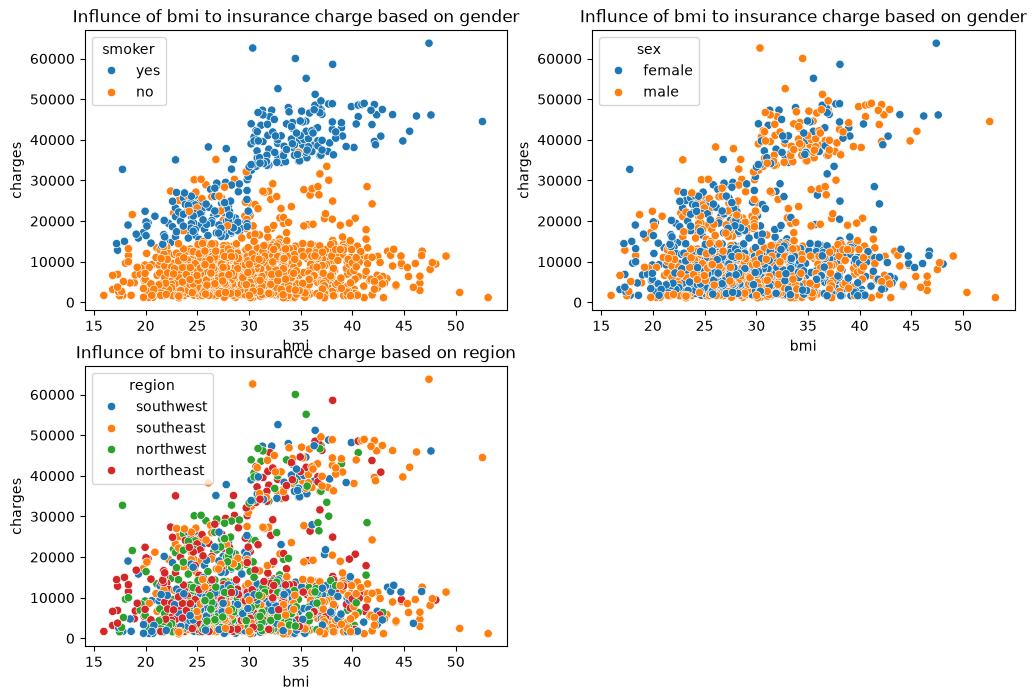

In [15]:
plt.figure(figsize=(12,8))
plt.subplot(221)
plt.title("Influnce of bmi to insurance charge based on gender")
sns.scatterplot(df, x="bmi", y="charges", hue="smoker")

plt.subplot(222)
plt.title("Influnce of bmi to insurance charge based on gender")
sns.scatterplot(df, x="bmi", y="charges", hue="sex")


plt.subplot(223)
plt.title("Influnce of bmi to insurance charge based on region")
sns.scatterplot(df, x="bmi", y="charges", hue="region")

In [16]:
## Train test split
from sklearn.model_selection import train_test_split

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=44)

In [17]:
# Feature transform

from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_feature = [ "age", "bmi", "children" ]
cat_feature = ["sex", "region", "smoker"]


transforms = {}
for i in num_feature:
    trans = StandardScaler()
    X_train[i] = trans.fit_transform(X_train[[i]])
    X_test[i] = trans.transform(X_test[[i]])
    transforms[i] = trans
    
for i in cat_feature:
    trans = OneHotEncoder(drop="first", sparse_output=False)
    encoded_array = trans.fit_transform(X_train[[i]])
    feature_names = trans.get_feature_names_out([i])
    encoded_df = pd.DataFrame(encoded_array, columns=feature_names, index=X_train.index)
    X_train = X_train.drop(i, axis=1).join(encoded_df)
    encoded_array = trans.transform(X_test[[i]])
    feature_names = trans.get_feature_names_out([i])
    encoded_df = pd.DataFrame(encoded_array, columns=feature_names, index=X_test.index)
    X_test = X_test.drop(i, axis=1).join(encoded_df)
    transforms[i] = trans
    

In [18]:
print(X_train.head())
print(X_test.head())
print(y_train.head())
print(y_test.head())

           age       bmi  children  sex_male  region_northwest  \
709  -0.233282 -0.506913 -0.913414       0.0               0.0   
1253  0.048740 -0.247236  2.402170       0.0               0.0   
917   0.401268 -1.313410 -0.913414       1.0               0.0   
723  -1.431875  0.768169 -0.913414       1.0               0.0   
643  -1.149853  0.694927  1.573274       0.0               1.0   

      region_southeast  region_southwest  smoker_yes  
709                0.0               0.0         0.0  
1253               0.0               1.0         0.0  
917                0.0               0.0         1.0  
723                0.0               1.0         0.0  
643                0.0               0.0         0.0  
           age       bmi  children  sex_male  region_northwest  \
440  -0.585809  0.315398 -0.084518       0.0               1.0   
1203  0.824301  0.252144 -0.084518       1.0               0.0   
821  -0.938337 -2.183162 -0.913414       1.0               1.0   
731   0.9

In [19]:
## Train
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae}")
print(f"RMSE: {mse}")
print(f"R² Score: {r2}")

MAE: 3929.6499184907534
RMSE: 30714880.38406558
R² Score: 0.7811956027975958
